### Top Rows

In [176]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="kPEX")
# df = pd.read_excel(file_path, sheet_name="UMKP+")
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = df[f"{v}-S-bnb"]=="prep"
    
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
df.head()

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/668701290.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/668701290.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/668701290.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain 

,dataset,k,n,m,d_avg,d_max,core_number,shell_sizes,v0-S-heur-kp,v0-S-mkp,v0-S-heur,v0-S-ctcp,v0-S-bnb,v0-S-total,v0-R-heur-kp,v0-R-mkp,v0-R-heur,v0-R-ctcp,v0-R-bnb,v0-R-total,v0-P-heur-kp,v0-P-mkp,v0-P-heur,v0-P-ctcp,v0-P-bnb,v0-P-total,v1-S-heur-kp,v1-S-mkp,v1-S-heur,v1-S-ctcp,v1-S-bnb,v1-S-total,v1-R-heur-kp,v1-R-mkp,v1-R-heur,v1-R-ctcp,v1-R-bnb,v1-R-total,v1-P-heur-kp,v1-P-mkp,v1-P-heur,v1-P-ctcp,v1-P-bnb,v1-P-total,v2-S-heur-kp,v2-S-mkp,v2-S-heur,v2-S-ctcp,v2-S-bnb,v2-S-total,v2-R-heur-kp,v2-R-mkp,v2-R-heur,v2-R-ctcp,v2-R-bnb,v2-R-total,v2-P-heur-kp,v2-P-mkp,v2-P-heur,v2-P-ctcp,v2-P-bnb,v2-P-total,v3-S-heur-kp,v3-S-mkp,v3-S-heur,v3-S-ctcp,v3-S-bnb,v3-S-total,v3-R-heur-kp,v3-R-mkp,v3-R-heur,v3-R-ctcp,v3-R-bnb,v3-R-total,v3-P-heur-kp,v3-P-mkp,v3-P-heur,v3-P-ctcp,v3-P-bnb,v3-P-total,v0-prep,v0-ctcp,v0-heur,v1-prep,v1-ctcp,v1-heur,v2-prep,v2-ctcp,v2-heur,v3-prep,v3-ctcp,v3-heur,v0-init,v1-init,v2-init,v3-init
0,12month1,20,52328,1585220,30.3,9214,57,"[(19,52328),(20,48272),(21,44653),(22,41313),(...",40,40,118.6,0.2,0.0,118.7,40,40,121.3,0.2,0.0,121.5,40,40,117.5,0.2,0.0,117.6,40,40,119.6,1.3,0.0,120.8,40,40,123.9,1.3,0.0,125.2,40,40,121.0,1.3,0.0,122.3,38,40,3.3,0.2,46.9,50.4,38,40,3.3,0.2,46.5,50.0,38,40,3.5,0.2,51.3,55.0,38,40,3.3,1.6,48.4,53.3,38,40,3.5,1.6,52.8,57.9,38,40,3.5,1.6,52.0,57.1,True,0.2,119.1,True,1.3,121.5,False,0.2,3.4,False,1.6,3.4,119.3,122.8,3.6,5.1
1,130bit,8,584,6059,10.4,322,12,"[(8,584),(9,583),(10,580),(11,566),(12,509)]",15,15,0.0,0.0,0.4,0.5,15,15,0.0,0.0,0.9,1.0,15,15,0.0,0.0,1.7,1.7,15,15,0.1,0.0,0.4,0.5,15,15,0.1,0.0,0.9,1.0,15,15,0.1,0.0,1.7,1.7,14,15,0.0,0.0,2.4,2.4,14,15,0.0,0.0,9.4,9.4,14,15,0.0,0.0,24.1,24.1,14,15,0.0,0.0,2.4,2.4,14,15,0.0,0.0,9.5,9.5,14,15,0.0,0.0,25.6,25.7,False,0.0,0.0,False,0.0,0.1,False,0.0,0.0,False,0.0,0.0,0.1,0.1,0.0,0.0
2,130bit,9,584,6059,10.4,322,12,"[(8,584),(9,583),(10,580),(11,566),(12,509)]",16,16,0.1,0.0,5.1,5.2,16,16,0.1,0.0,24.9,24.9,16,16,0.1,0.0,45.4,45.5,16,16,0.1,0.0,5.1,5.2,16,16,0.1,0.0,23.3,23.4,16,16,0.1,0.0,45.5,45.6,16,16,0.0,0.0,4.9,4.9,16,16,0.0,0.0,24.1,24.1,16,16,0.0,0.0,46.2,46.2,16,16,0.0,0.0,4.9,4.9,16,16,0.0,0.0,24.1,24.1,16,16,0.0,0.0,46.3,46.3,False,0.0,0.1,False,0.0,0.1,False,0.0,0.0,False,0.0,0.0,0.1,0.1,0.0,0.0
3,130bit,10,583,6051,10.4,321,12,"[(9,583),(10,580),(11,566),(12,509)]",17,17,0.0,0.0,2.0,2.0,17,17,0.0,0.0,11.6,11.6,17,17,0.0,0.0,13.3,13.3,17,17,0.0,0.0,2.1,2.1,17,17,0.0,0.0,11.6,11.6,17,17,0.0,0.0,12.5,12.5,17,18,0.0,0.0,113.3,113.3,1800,1800,1800.0,1800.0,1800.0,1800.0,1800,1800,1800.0,1800.0,1800.0,1800.0,17,18,0.0,0.0,113.6,113.6,1800,1800,1800.0,1800.0,1800.0,1800.0,1800,1800,1800.0,1800.0,1800.0,1800.0,False,0.0,0.0,False,0.0,0.0,False,0.0,0.0,False,0.0,0.0,0.0,0.0,0.0,0.0
4,144.0,4,144319,1072349,7.4,26,9,"[(7,144319),(8,143537),(9,132943)]",10,10,0.4,0.2,0.5,1.0,10,10,0.4,0.2,0.4,1.0,10,10,0.4,0.2,0.5,1.0,10,10,0.4,0.2,0.4,1.1,10,10,0.4,0.2,0.5,1.1,10,10,0.4,0.2,0.5,1.1,9,10,0.4,0.3,0.5,1.1,9,10,0.4,0.3,0.5,1.1,9,10,0.4,0.3,0.5,1.1,9,10,0.4,0.3,0.5,1.1,9,10,0.4,0.3,0.5,1.1,9,10,0.4,0.3,0.5,1.1,False,0.2,0.4,False,0.2,0.4,False,0.3,0.4,False,0.3,0.4,0.6,0.6,0.7,0.6


In [175]:
# for v in versions: 
cols = [f"v1-{b}-mkp" for b in "S P".split()]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
df.loc[mask, cols+["dataset", "k", "v0-S-total"]]
# mask.sum()

,v1-S-mkp,v1-P-mkp,dataset,k,v0-S-total


### Varying Ratio Threshold


=== Threshold 2 Analysis ===
v0-heur wins: 66
v2-heur wins: 942

--- Weaker side: v0-heur ---


,dataset,k,v0-heur,v2-heur,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
888,degme,8,0.0,19.6,0.0,19.6,0.1,19.7,False,False,540.2,1153.0,573.9,1079.7,543.7,1025.1
889,degme,9,0.0,19.6,0.0,19.6,0.1,19.7,False,False,515.6,1063.7,527.8,1092.7,530.8,1006.4
890,degme,10,0.0,19.6,0.0,19.6,0.1,19.7,False,False,495.8,1022.1,524.2,1091.9,512.6,968.7
887,degme,7,0.0,19.5,0.0,19.5,0.1,19.7,False,False,565.6,1012.0,576.0,1137.9,558.9,1058.0
886,degme,6,0.0,19.1,0.0,19.1,0.1,19.2,False,False,632.7,630.2,566.9,581.2,648.9,597.0
1211,ESOC,9,0.0,6.3,0.0,6.3,0.1,6.5,False,False,186.1,204.4,184.7,205.6,182.5,199.2
1219,EternityII_E,6,0.0,4.1,0.0,4.1,0.0,4.2,False,False,167.4,154.2,165.0,180.2,317.3,337.0
2009,lp_osa_14,7,0.0,3.2,0.0,3.2,0.0,3.2,False,False,47.7,49.7,50.5,51.6,51.2,49.6
3000,sc-msdoor,20,0.0,3.2,0.0,3.2,0.3,3.5,False,False,8.3,16.0,6.0,11.6,6.1,11.5
1220,EternityII_E,7,0.0,2.6,0.0,2.6,0.0,2.6,False,False,88.5,245.0,86.9,1800.0,95.5,1800.0



--- Stronger side: v2-heur ---


,dataset,k,v0-heur,v2-heur,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4280,wikipedia_link_sr,6,188.0,0.1,188.0,0.1,231.2,44.0,True,True,238.0,43.3,231.9,43.9,223.8,44.7
4282,wikipedia_link_sr,8,189.9,0.1,189.9,0.1,233.9,45.0,True,True,225.2,44.6,231.2,44.3,245.1,46.3
4283,wikipedia_link_sr,9,182.9,0.1,182.9,0.1,225.4,44.2,True,True,226.3,44.7,224.7,43.3,225.2,44.6
4281,wikipedia_link_sr,7,180.9,0.1,180.9,0.1,224.5,44.0,True,True,215.5,44.4,225.0,43.3,232.9,44.4
4285,wikipedia_link_sr,15,180.1,0.1,180.1,0.1,223.7,44.6,True,True,233.0,45.4,218.2,44.8,219.9,43.7
4284,wikipedia_link_sr,10,178.0,0.1,178.0,0.1,221.7,44.5,True,True,214.8,44.7,218.2,44.0,232.0,44.9
4279,wikipedia_link_sr,5,166.8,0.1,166.8,0.1,204.3,38.0,True,True,205.3,38.3,200.3,37.7,207.3,38.0
4286,wikipedia_link_sr,20,178.9,0.1,178.9,0.1,221.7,45.8,True,True,222.4,44.9,221.6,44.4,221.0,48.0
4276,wikipedia_link_sr,2,173.8,0.2,173.8,0.2,211.3,38.0,True,True,211.4,37.9,210.6,38.0,212.0,38.0
12,162bit,7,2.0,0.0,2.0,0.0,2.0,0.0,False,False,300.8,283.3,1800.0,1800.0,1800.0,1800.0


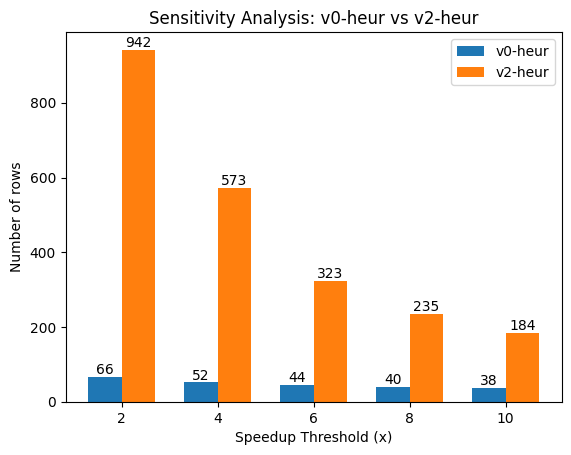

In [184]:

# =========================
# CONFIG
# =========================
col_a = "v0-heur"
col_b = "v2-heur"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================


df_filtered = df[(df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)].copy()
# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"

pd.set_option('display.float_format', '{:.1f}'.format)

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

max_len = 25

def format_df(df_in):
    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        )
    )[[
        "dataset", "k", col_a, col_b,
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]

# =========================
# Show BOTH sides
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(format_df(a_wins.sort_values(by="speedup_a", ascending=False)))

    print("\n--- Side B (>= threshold) ---")
    display_scroll(format_df(b_wins.sort_values(by="speedup_b", ascending=False)))

else:
    # Weaker
    if weaker == "A":
        weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b
    else:
        weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

    print(f"\n--- Weaker side: {weaker_name} ---")
    display_scroll(format_df(weaker_df))

    print(f"\n--- Stronger side: {stronger_name} ---")
    display_scroll(format_df(stronger_df))
# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

# Annotate
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()